In [1]:
import os
import glob
import cv2
import random

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
train_path = r"D:\Data_Science\Deep Learning\Brain Tumour Classification Files\archive\Training"
test_path = r"D:\Data_Science\Deep Learning\Brain Tumour Classification Files\archive\Testing"

classes = [
   'glioma', 'meningioma', 'notumor', 'pituitary'
]

In [3]:

print("Training folders:")
print(os.listdir(train_path))

print("\nTesting folders:")
print(os.listdir(test_path))

Training folders:
['glioma', 'meningioma', 'notumor', 'pituitary']

Testing folders:
['glioma', 'meningioma', 'notumor', 'pituitary']


In [4]:
for cls in classes:

    train_count = len(os.listdir(os.path.join(train_path, cls)))
    test_count = len(os.listdir(os.path.join(test_path, cls)))

    print(
        cls,
        "Training:", train_count,
        "Testing:", test_count
    )

glioma Training: 1400 Testing: 400
meningioma Training: 1400 Testing: 400
notumor Training: 1400 Testing: 400
pituitary Training: 1400 Testing: 400


In [5]:
glioma_train = glob.glob(os.path.join(train_path, "glioma", "*"))
meningioma_train = glob.glob(os.path.join(train_path, "meningioma", "*"))
no_tumor_train = glob.glob(os.path.join(train_path, "notumor", "*"))
pituitary_train = glob.glob(os.path.join(train_path, "pituitary", "*"))

print("Glioma:", len(glioma_train))
print("Meningioma:", len(meningioma_train))
print("No Tumor:", len(no_tumor_train))
print("Pituitary:", len(pituitary_train))

Glioma: 1400
Meningioma: 1400
No Tumor: 1400
Pituitary: 1400


In [6]:
#glob.glob("Training/glioma_tumor/*")

In [7]:
glioma_test = glob.glob(os.path.join(test_path, "glioma", "*"))
meningioma_test = glob.glob(os.path.join(test_path, "meningioma", "*"))
no_tumor_test = glob.glob(os.path.join(test_path, "notumor", "*"))
pituitary_test = glob.glob(os.path.join(test_path, "pituitary", "*"))

print("Glioma:", len(glioma_test))
print("Meningioma:", len(meningioma_test))
print("No Tumor:", len(no_tumor_test))
print("Pituitary:", len(pituitary_test))

Glioma: 400
Meningioma: 400
No Tumor: 400
Pituitary: 400


In [8]:
print("TRAINING DATA")

for cls in classes:
    folder = os.path.join(train_path, cls)
    print(cls, len(os.listdir(folder)))

print("\nTESTING DATA")

for cls in classes:
    path = os.path.join(test_path, cls)
    print(cls, ":", len(os.listdir(folder)))

TRAINING DATA
glioma 1400
meningioma 1400
notumor 1400
pituitary 1400

TESTING DATA
glioma : 1400
meningioma : 1400
notumor : 1400
pituitary : 1400


In [12]:
print("X_train images :", len(X_train_list))
print("y_train labels:", len(y_train_list))

print("X_test images  :", len(X_test_list))
print("y_test labels :", len(y_test_list))

X_train images : 5600
y_train labels: 5600
X_test images  : 1600
y_test labels : 1600


In [10]:
X_train_list = []
y_train_list = []

for label, cls in enumerate(classes):

    folder = os.path.join(train_path, cls)

    for image_path in glob.glob(os.path.join(folder, "*")):

        image = cv2.imread(image_path)

        if image is not None:
            X_train_list.append(image)
            y_train_list.append(label)

print("Training images:", len(X_train_list))
print("Training labels:", len(y_train_list))

Training images: 5600
Training labels: 5600


In [11]:
X_test_list = []
y_test_list = []

for label, cls in enumerate(classes):

    folder = os.path.join(test_path, cls)

    for image_path in glob.glob(os.path.join(folder, "*")):

        image = cv2.imread(image_path)

        if image is not None:
            X_test_list.append(image)
            y_test_list.append(label)

print("Testing images:", len(X_test_list))
print("Testing labels:", len(y_test_list))

Testing images: 1600
Testing labels: 1600


In [13]:
from sklearn.utils import shuffle
from sklearn.metrics import confusion_matrix, classification_report

In [14]:
X_train_list, y_train_list = shuffle(
    X_train_list,
    y_train_list,
    random_state=42
)

X_test_list, y_test_list = shuffle(
    X_test_list,
    y_test_list,
    random_state=42
)

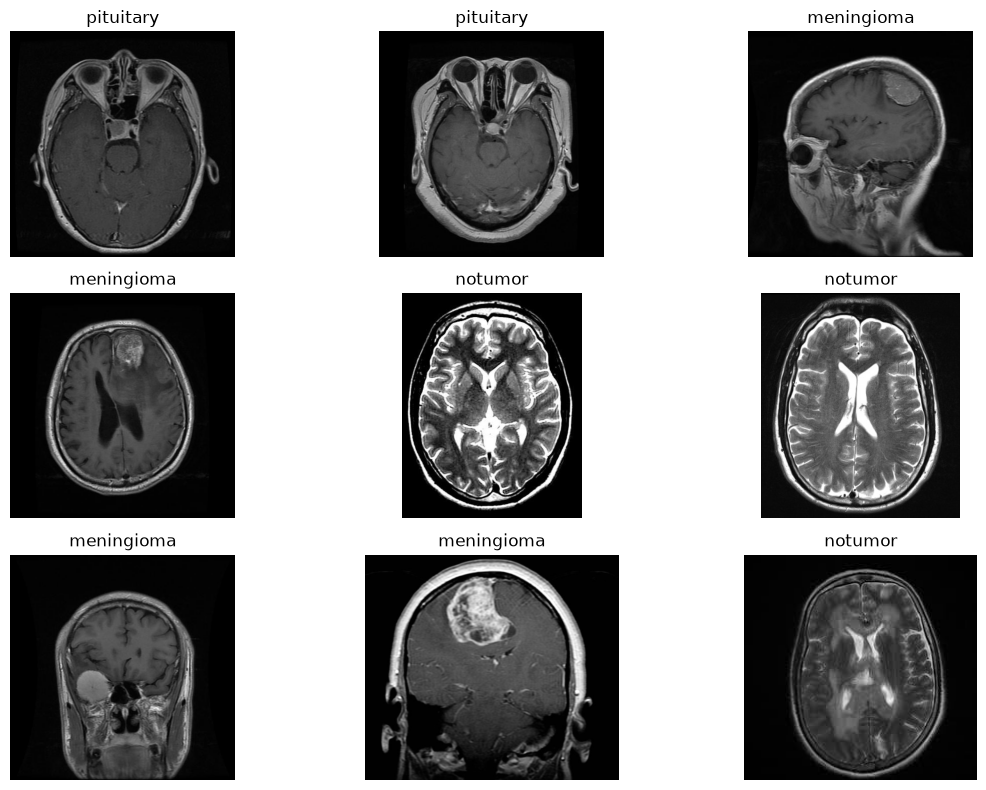

In [15]:
plt.figure(figsize=(12, 8))

for i in range(9):

    plt.subplot(3, 3, i + 1)

    image = cv2.cvtColor(X_train_list[i], cv2.COLOR_BGR2RGB)

    plt.imshow(image)
    plt.title(classes[y_train_list[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [16]:
for i in range(10):
    print(i, X_train_list[i].shape)

0 (512, 512, 3)
1 (512, 512, 3)
2 (512, 512, 3)
3 (512, 512, 3)
4 (449, 359, 3)
5 (380, 336, 3)
6 (512, 512, 3)
7 (1019, 1149, 3)
8 (221, 228, 3)
9 (512, 512, 3)


In [17]:
X_train = []

for image in X_train_list:

    image = cv2.resize(image, (224, 224))

    X_train.append(image)

X_train = np.array(X_train)

In [18]:
X_test = []

for image in X_test_list:

    image = cv2.resize(image, (224, 224))

    X_test.append(image)

X_test = np.array(X_test)

In [19]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

X_train: (5600, 224, 224, 3)
X_test: (1600, 224, 224, 3)


In [20]:
y_train = np.array(y_train_list)
y_test = np.array(y_test_list)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

y_train: (5600,)
y_test: (1600,)


In [21]:
X_train = X_train / 255.0
X_test = X_test / 255.0

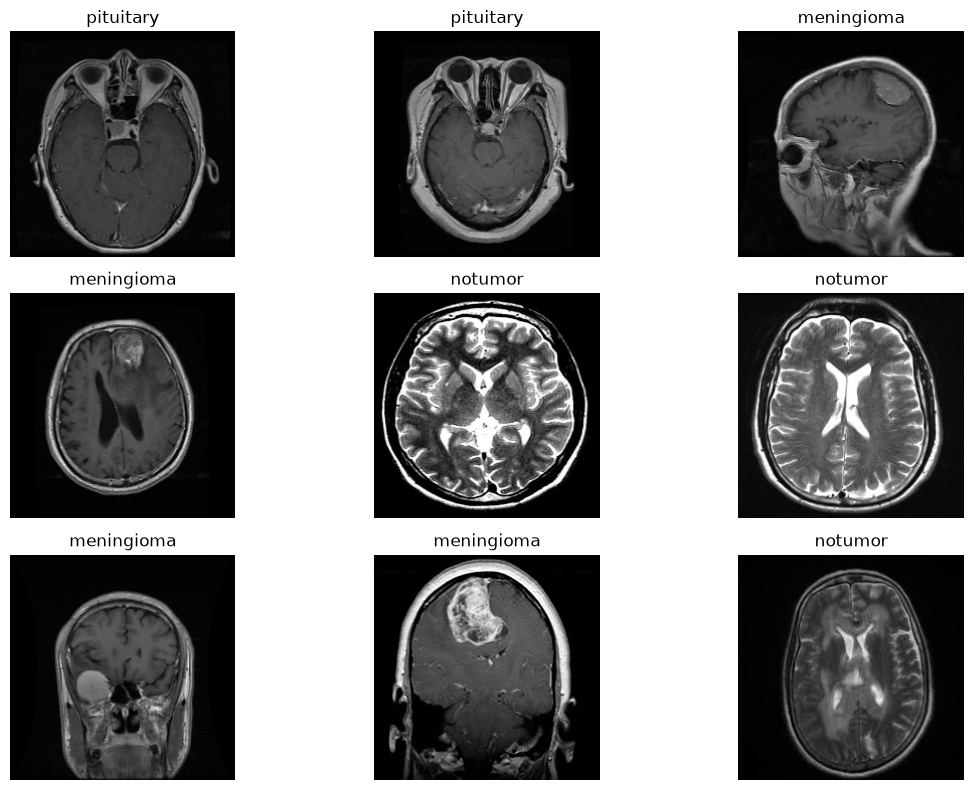

In [22]:
plt.figure(figsize = (12, 8))

for i in range(9):

    plt.subplot(3, 3, i+1)
    plt.imshow(X_train[i])
    plt.title(classes[y_train[i]])
    plt.axis('off')

plt.tight_layout()
plt.show()

In [23]:
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (5600, 224, 224, 3)
y_train shape: (5600,)
X_test shape: (1600, 224, 224, 3)
y_test shape: (1600,)


In [24]:
from tensorflow.keras.models import Sequential

from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout



In [25]:
model = Sequential ([
    Conv2D
    (32, (3, 3), activation = 'relu', input_shape = (224,224,3) ),
    
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation = 'relu'),
    
    MaxPooling2D((2, 2)),
    Conv2D(128, (3, 3), activation = 'relu'),

    MaxPooling2D((2, 2)),
    Conv2D(256, (3, 3), activation = 'relu'),

    MaxPooling2D((2,2)),
    Flatten(), Dense(128, activation = 'relu'),
    Dropout(0.5),
    Dense(4, activation = 'softmax')
])

C:\Users\Jersin\anaconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [26]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [27]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 222, 222, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 111, 111, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 109, 109, 64)        │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 54, 54, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 52, 52, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 26, 26, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 24, 24, 256)         │         295,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 12, 12, 256)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 36864)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │       4,718,720 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 4)                   │             516 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 5,107,652 (19.48 MB)

 Trainable params: 5,107,652 (19.48 MB)

 Non-trainable params: 0 (0.00 B)

In [28]:
history = model.fit(
    X_train,
    y_train,
    epochs=15,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 103s 717ms/step - accuracy: 0.6228 - loss: 0.8714 - val_accuracy: 0.7580 - val_loss: 0.5898
Epoch 2/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 92s 655ms/step - accuracy: 0.7859 - loss: 0.5346 - val_accuracy: 0.8402 - val_loss: 0.4283
Epoch 3/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 117s 839ms/step - accuracy: 0.8415 - loss: 0.4077 - val_accuracy: 0.8679 - val_loss: 0.3605
Epoch 4/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 122s 872ms/step - accuracy: 0.8772 - loss: 0.3241 - val_accuracy: 0.9045 - val_loss: 0.2788
Epoch 5/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 95s 676ms/step - accuracy: 0.9025 - loss: 0.2571 - val_accuracy: 0.9116 - val_loss: 0.2383
Epoch 6/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 92s 657ms/step - accuracy: 0.9237 - loss: 0.1912 - val_accuracy: 0.9214 - val_loss: 0.2357
Epoch 7/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 102s 730ms/step - accuracy: 0.9344 - loss: 0.1722 - val_accuracy: 0.9321 - val_loss: 0.2104
Epoch 8/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 97s 695ms/step - accuracy: 0.9480 - los

In [29]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

50/50 ━━━━━━━━━━━━━━━━━━━━ 8s 151ms/step - accuracy: 0.8838 - loss: 1.1498
Test Loss: 1.149794578552246
Test Accuracy: 0.8837500214576721


In [33]:
predictions = model.predict(X_test)

print(predictions)

50/50 ━━━━━━━━━━━━━━━━━━━━ 7s 143ms/step
[[5.6581055e-03 9.9428260e-01 5.3091193e-05 6.2787803e-06]
 [1.4127842e-07 4.9329191e-02 9.5067060e-01 8.6044025e-08]
 [9.9666059e-01 3.3381397e-03 6.4824383e-07 6.5912127e-07]
 ...
 [2.0883162e-24 1.1807370e-13 1.0000000e+00 5.6594381e-33]
 [8.8190940e-13 4.8240179e-10 8.2574597e-10 1.0000000e+00]
 [1.3962297e-16 9.4095463e-05 9.9990594e-01 6.7411343e-21]]


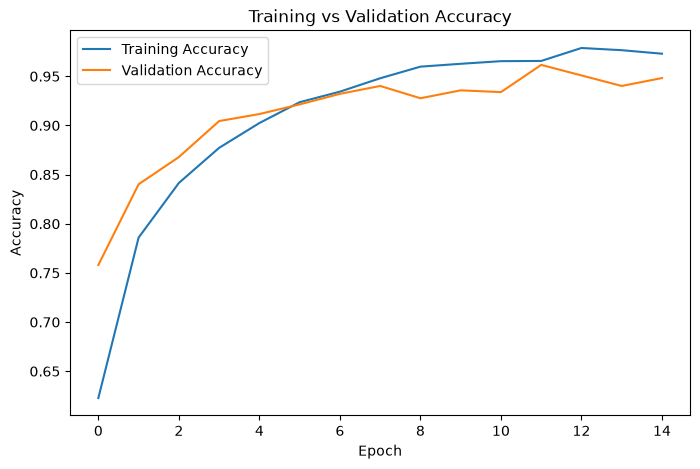

In [30]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")

plt.legend()
plt.show()

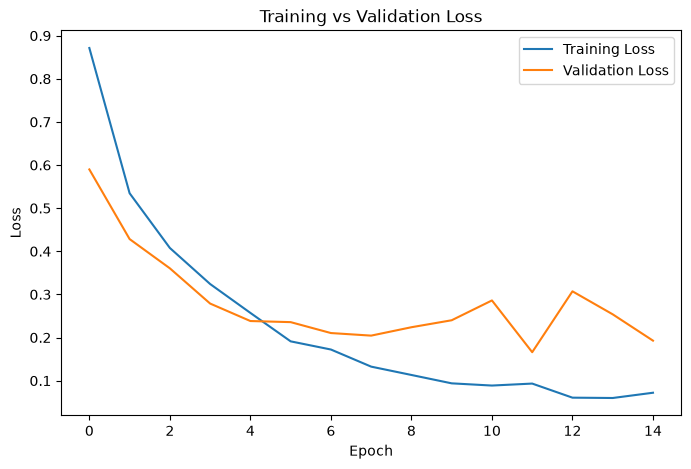

In [31]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")

plt.legend()
plt.show()

In [34]:
y_pred = np.argmax(predictions, axis=1)

print(y_pred[:5])

[1 2 0 0 2]


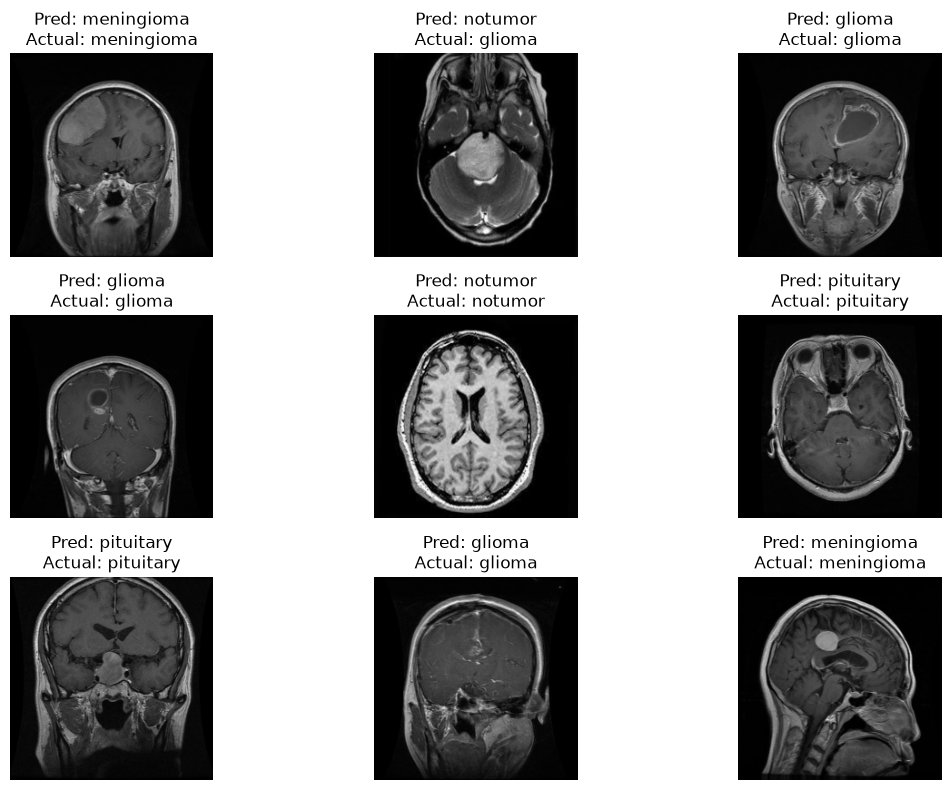

In [35]:
plt.figure(figsize=(12, 8))

for i in range(9):

    plt.subplot(3, 3, i + 1)

    plt.imshow(X_test[i])

    predicted_label = classes[y_pred[i]]
    actual_label = classes[y_test[i]]

    plt.title(
        f"Pred: {predicted_label}\nActual: {actual_label}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

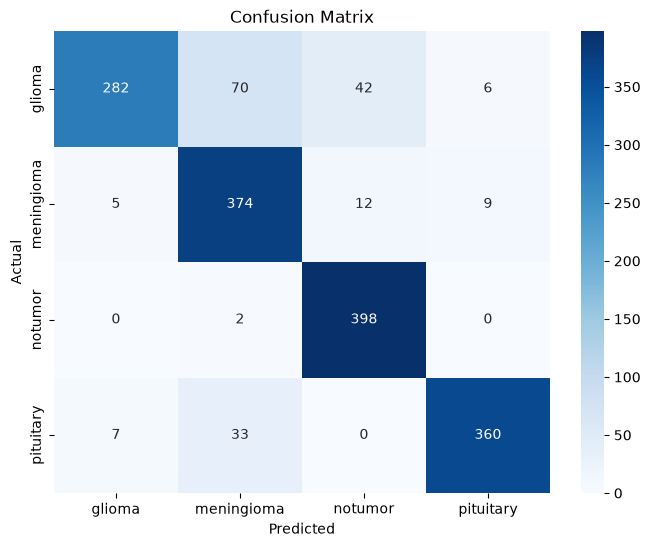

In [36]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

In [37]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=classes
    )
)

              precision    recall  f1-score   support

      glioma       0.96      0.70      0.81       400
  meningioma       0.78      0.94      0.85       400
     notumor       0.88      0.99      0.93       400
   pituitary       0.96      0.90      0.93       400

    accuracy                           0.88      1600
   macro avg       0.90      0.88      0.88      1600
weighted avg       0.90      0.88      0.88      1600



In [ ]:
# Save the trained LSTM model
model.save("Brain.keras")

print("Model saved successfully!")

In [43]:
image_path = input("Enter MRI image path: ")

image = cv2.imread(image_path)

if image is None:
    print("Image not found!")
else:
    image = cv2.resize(image, (224, 224))
    image = image / 255.0

    image = np.expand_dims(image, axis=0)

    prediction = model.predict(image)

    index = np.argmax(prediction)

    print("Predicted Class:", classes[index])
    print("Confidence:", prediction[0][index] * 100, "%")

KeyboardInterrupt: Interrupted by user